# Dividing Lines: what separates Luminal A from Luminal B breast tumours?

**Computing for Bioinformatics · Group project**

| Student ID | Name |
|---|---|
| 166234 | Wachira Njoroge |
| 168327 | Stacy Akinyi |
| 161031 | Marie Hoppe Okeyo |
| 164856 | Diana Mucheke |
| 166078 | Mathenge Gitahi |
| 161790 | Anise Kimani |

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DiorWachira/dividing-lines/blob/main/dividing_lines.ipynb) Run with *Runtime → Run all*; the data downloads automatically.

## Stage 1 · Question and objectives

**Question:** which gene-expression differences distinguish Luminal A and Luminal B breast tumours, and how well can they classify the two groups?

1. Compare gene expression between the two subtypes.
2. Find genes that differ significantly, correcting for multiple testing.
3. Interpret the strongest differences by gene function.
4. Compare a classifier against proper baselines.

**Hypothesis:** the subtypes differ mainly in how fast the cells divide, so a few proliferation genes will do most of the classifying.

**Background:** Luminal A tumours grow slowly and usually get hormone therapy alone, while Luminal B tumours grow faster and often get chemotherapy too.

**Honesty note:** the subtypes were originally *defined* from gene expression, so separating them is partly guaranteed; we therefore measure *which* genes do the work.

**Declared before looking at results:** the 21 PAM50 proliferation genes (*ANLN, BIRC5, CCNB1, CCNE1, CDC20, CDC6, NUF2, CENPF, CEP55, EXO1, KIF2C, NDC80, MELK, MKI67, MYBL2, ORC6, PTTG1, RRM2, TYMS, UBE2C, UBE2T*), the GO terms *cell cycle* (GO:0007049) and *cell division* (GO:0051301), and FDR < 5%.

**Glossary**

| Term | Meaning |
|---|---|
| Gene | A section of DNA that holds the recipe for one protein. |
| Gene expression | How strongly a gene is switched on right now. |
| Microarray | A chip of ~54,000 tiny light meters, one per probe, that glow brighter the more a gene is expressed. |
| Probe | One spot on the chip that measures one gene. |
| Tumour subtype | A group of tumours that behave alike and get similar treatment. |
| Luminal A | Hormone-sensitive breast cancer that grows slowly. |
| Luminal B | Hormone-sensitive breast cancer that grows faster. |
| Proliferation | How fast cells divide. |
| Differential expression | A gene that is reliably more active in one group than the other. |
| p-value | How often chance alone would produce a difference this big. |
| Multiple-testing correction | Adjusting p-values because thousands of tests produce lucky results. |
| False discovery rate (FDR) | The expected share of false alarms among the genes we call significant. |
| Cross-validation | Training on some samples and testing on the hidden rest, in rotation. |
| Data leakage | Test samples influencing training, which inflates the score. |
| Baseline | A deliberately simple model to compare against. |

In [1]:
import gzip, io, time, urllib.request, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

SEED = 45827
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
DATA, FIGS = Path("data"), Path("figures")
DATA.mkdir(exist_ok=True); FIGS.mkdir(exist_ok=True)

# One colour scheme: indigo = Luminal A, rose = Luminal B, brown = proliferation genes
LUM_A, LUM_B, PROLIF, INK, MUTED = "#4549A6", "#D04A86", "#7E4310", "#1F1C3D", "#8A86A0"
PAL = {"Luminal A": LUM_A, "Luminal B": LUM_B}
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", dpi=150)
    plt.show()

def download(url, path):
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")

## Stage 2 · Data acquisition
- **What:** download GEO series GSE45827 (Institut Curie, Affymetrix U133 Plus 2.0, GPL570) and read it into tables.
- **Why:** every later step depends on reading the subtype labels correctly.
- **Look for:** exactly 29 Luminal A and 30 Luminal B; anything else stops the notebook.

In [2]:
MATRIX_URL = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE45nnn/GSE45827/matrix/GSE45827_series_matrix.txt.gz"
download(MATRIX_URL, DATA / "GSE45827_series_matrix.txt.gz")
lines = gzip.open(DATA / "GSE45827_series_matrix.txt.gz", "rt", encoding="utf-8").read().splitlines()
start, end = lines.index("!series_matrix_table_begin"), lines.index("!series_matrix_table_end")

series_meta, sample_meta, seen = {}, {}, {}
for line in lines[:start]:
    key, *vals = line.split("\t")
    vals = [v.strip('"') for v in vals]
    if key.startswith("!Series_"):
        series_meta.setdefault(key[8:], []).extend(vals)
    elif key.startswith("!Sample_"):
        seen[key] = seen.get(key, 0) + 1
        sample_meta[key[8:] + ("" if seen[key] == 1 else f"_{seen[key]}")] = vals
sample_meta = pd.DataFrame(sample_meta).set_index("geo_accession", drop=False)
expr_all = pd.read_csv(io.StringIO("\n".join(lines[start + 1:end])), sep="\t", index_col=0)
expr_all.columns, expr_all.index = expr_all.columns.str.strip('"'), expr_all.index.str.strip('"')
print("Expression table:", expr_all.shape, "(probes × samples)")

GSE45827_series_matrix.txt.gz: 15.7 MB


Expression table: (29873, 155) (probes × samples)


In [3]:
# Describe every variable (personal contact details withheld)
hidden = ("contact_email", "contact_phone", "contact_fax")
print("SERIES FIELDS")
for k, v in series_meta.items():
    print(f"  {k:24s}", "[withheld]" if k in hidden else " | ".join(v)[:110])
print("\nSAMPLE FIELDS (distinct values · example)")
for c in sample_meta.columns:
    print(f"  {c:26s} {sample_meta[c].nunique():>4} · {'[withheld]' if c.startswith(hidden) else sample_meta[c].iloc[0][:70]}")
print("\nSUBMITTERS' PROCESSING (theirs, not ours):\n", sample_meta["data_processing"].iloc[0])

SERIES FIELDS
  title                    Expression data from Breast cancer subtypes
  geo_accession            GSE45827
  status                   Public on Mar 24 2016
  submission_date          Apr 05 2013
  last_update_date         Mar 25 2019
  pubmed_id                27006338
  summary                  Expression data from Breast cancer subtypes
  overall_design           In a cohort study of primary invasive breast cancer (41 TN, 30 HER2, 29 Luminal A and 30 Luminal B) as well as
  type                     Expression profiling by array
  contributor              Tina,,Gruosso | Yann,,Kieffer | Thierry,,Dubois | Fatima,,Mechta-Grigoriou
  sample_id                GSM1116084 GSM1116085 GSM1116086 GSM1116087 GSM1116088 GSM1116089 GSM1116090 GSM1116091 GSM1116092 GSM1116093 
  contact_name             Fatima,,Mechta-Grigoriou
  contact_email            [withheld]
  contact_phone            [withheld]
  contact_fax              [withheld]
  contact_laboratory       Stress and Cancer

In [4]:
field = lambda col, name: sample_meta[col].str.replace(rf"^{name}:\s*", "", regex=True)
sample_meta["subtype"] = field("characteristics_ch1_2", "tumor subtype")
sample_meta["batch"] = field("characteristics_ch1_3", "batch")
print(sample_meta["subtype"].value_counts().to_string())
n_a, n_b = (sample_meta.subtype == "Luminal A").sum(), (sample_meta.subtype == "Luminal B").sum()
assert (n_a, n_b) == (29, 30), f"Expected 29/30, got {n_a}/{n_b}"
print(f"\nCheck passed: {n_a} Luminal A and {n_b} Luminal B")

subtype
Basal                                41
Her2                                 30
Luminal B                            30
Luminal A                            29
cell origin: Breast carcinoma        12
N/A                                  11
cell origin: Breast mammary gland     2

Check passed: 29 Luminal A and 30 Luminal B


**What we found:** the NCBI download worked, so no fallback was needed. The file has 155 samples, and the labels give exactly 29 Luminal A and 30 Luminal B. The matrix holds 29,873 probes rather than 54,675, because the submitters had already removed noise-level probes. We use GSE45827 only and never merge it with GSE65194, which is the same patients reprocessed. NCBI places no restrictions on GEO data; we cite the submitters (Gruosso *et al.*, 2016, PMID 27006338). A cleaned copy of our 59 tumours is in `results/` for convenience.

## Stage 3 · Preprocessing and quality control
- **What:** keep the 59 luminal tumours, check the value scale, and drop missing and near-flat probes.
- **Why:** tests need comparable, sensibly scaled data, and flat probes only add false-positive risk.
- **Look for:** values already on a log₂ scale (about 0–16) and no tumour far from the rest.

In [5]:
meta = sample_meta.loc[sample_meta.subtype.isin(["Luminal A", "Luminal B"]), ["title", "subtype", "batch"]].copy()
expr = expr_all[meta.index]
print(f"Samples: {expr_all.shape[1]} → {expr.shape[1]}")

q = np.percentile(expr.values, [0, 50, 100])
print(f"Value range {q[0]:.1f} to {q[2]:.1f}, median {q[1]:.1f} →",
      "already log2 (GC-RMA), no transform" if q[2] < 100 else "raw, applying log2(x+1)")
if q[2] >= 100:
    expr = np.log2(expr.clip(lower=0) + 1)

n0 = len(expr); expr = expr.dropna(); n1 = len(expr)
expr = expr[expr.std(axis=1) >= 0.2]          # drop near-flat probes (label-free, so no bias)
print(f"Probes: {n0:,} → {n1:,} after missing values → {len(expr):,} after removing SD < 0.2")

Samples: 155 → 59
Value range -1.1 to 17.0, median 6.6 → already log2 (GC-RMA), no transform


Probes: 29,873 → 29,873 after missing values → 28,592 after removing SD < 0.2

In [6]:
# Odd tumours: flag any whose median or average correlation is > 3.5 robust SDs from the rest
corr = np.corrcoef(expr.T.values)
meta["median"] = expr.median().values
meta["mean_corr"] = (corr.sum(axis=1) - 1) / (len(corr) - 1)
rz = lambda x: (x - np.median(x)) / stats.median_abs_deviation(x, scale="normal")
flagged = meta.index[(np.abs(rz(meta["median"])) > 3.5) | (rz(meta.mean_corr) < -3.5)].tolist()
print("Flagged tumours:", flagged or "none")
print("Subtypes across lab batches:\n", pd.crosstab(meta.subtype, meta.batch).to_string())
print(f"Chi-square p = {stats.chi2_contingency(pd.crosstab(meta.subtype, meta.batch))[1]:.2f}")

Flagged tumours: none
Subtypes across lab batches:
 batch      1  2  3  4  5
subtype                 
Luminal A  4  6  6  8  5
Luminal B  6  7  7  4  6
Chi-square p = 0.74


**What we found:** 59 tumours remain. The values were already log₂ (GC-RMA), so we did not transform them. There were no missing values, and 1,281 near-flat probes were removed, leaving 28,592. No tumour was flagged, so all 59 are kept. The two subtypes are spread evenly over the lab batches (p = 0.74), so batch effects are unlikely to pose as biology.

## Stage 4 · Exploratory data analysis
- **What:** four plots: per-tumour boxplots, PCA, a heatmap, and the *MKI67* check.
- **Why:** plots reveal normalisation problems, label errors and the shape of the difference before any test.
- **Look for:** aligned medians, and *MKI67* (a marker of dividing cells) clearly higher in Luminal B.

In [7]:
# Platform annotation: which gene each probe measures
download("https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz", DATA / "GPL570.annot.gz")
al = gzip.open(DATA / "GPL570.annot.gz", "rt", encoding="utf-8").read().splitlines()
annot = pd.read_csv(io.StringIO("\n".join(al[al.index("!platform_table_begin") + 1:al.index("!platform_table_end")])),
                    sep="\t", index_col=0, dtype=str).fillna("")
symbol = annot["Gene symbol"].reindex(expr.index).fillna("")
symbols_of = symbol.str.split("///")
is_b = (meta.subtype == "Luminal B").values
order = meta.sort_values(["subtype", "median"]).index

GPL570.annot.gz: 8.5 MB


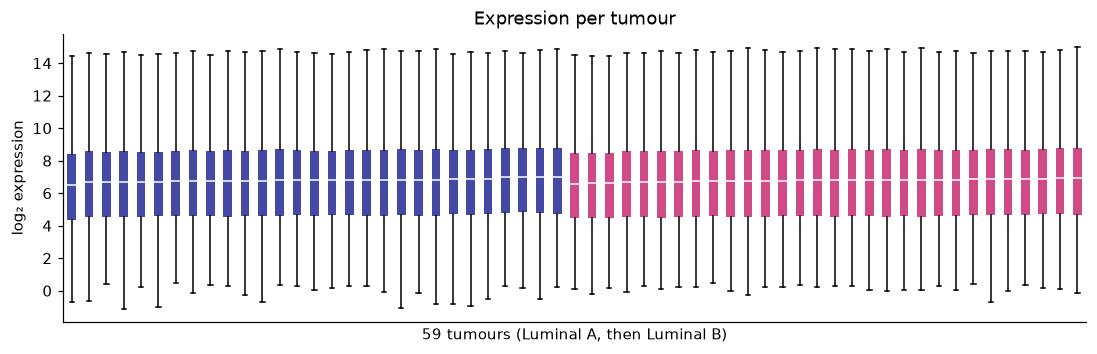

Caption: the medians line up, so the tumours are comparably normalised.


In [8]:
fig, ax = plt.subplots(figsize=(12, 3.4))
bp = ax.boxplot([expr[s] for s in order], showfliers=False, patch_artist=True, medianprops=dict(color="white"))
for box, s in zip(bp["boxes"], order):
    box.set(facecolor=PAL[meta.subtype[s]], edgecolor="none")
ax.set(title="Expression per tumour", xlabel="59 tumours (Luminal A, then Luminal B)", ylabel="log₂ expression", xticks=[])
save(fig, "04a_sample_boxplots")
print("Caption: the medians line up, so the tumours are comparably normalised.")

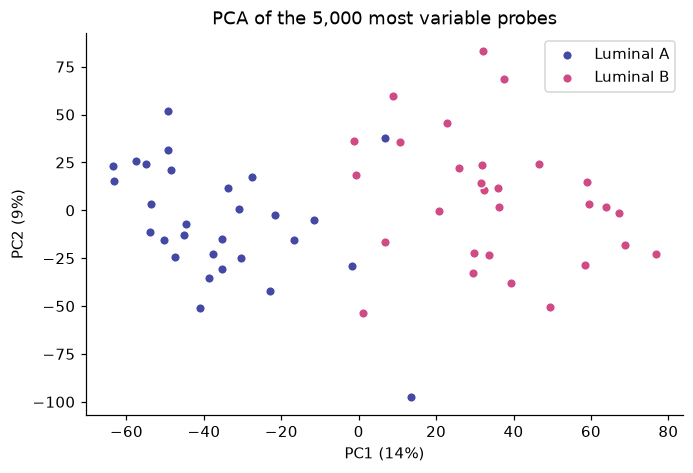

Caption: PC1 mostly separates the subtypes, but they touch in the middle: one spread, not two islands.


In [9]:
from sklearn.decomposition import PCA
top = expr.loc[expr.var(axis=1).nlargest(5000).index].T
pca = PCA(n_components=2, random_state=SEED).fit(top - top.mean())
pcs = pca.transform(top - top.mean())
pcs[:, 0] *= 1 if pcs[is_b, 0].mean() > 0 else -1          # put Luminal B on the right
fig, ax = plt.subplots(figsize=(7, 4.5))
for st in PAL:
    m = (meta.subtype == st).values
    ax.scatter(pcs[m, 0], pcs[m, 1], color=PAL[st], label=st, s=40, edgecolor="white")
ve = pca.explained_variance_ratio_
ax.set(title="PCA of the 5,000 most variable probes", xlabel=f"PC1 ({ve[0]:.0%})", ylabel=f"PC2 ({ve[1]:.0%})"); ax.legend()
save(fig, "04b_pca")
print("Caption: PC1 mostly separates the subtypes, but they touch in the middle: one spread, not two islands.")

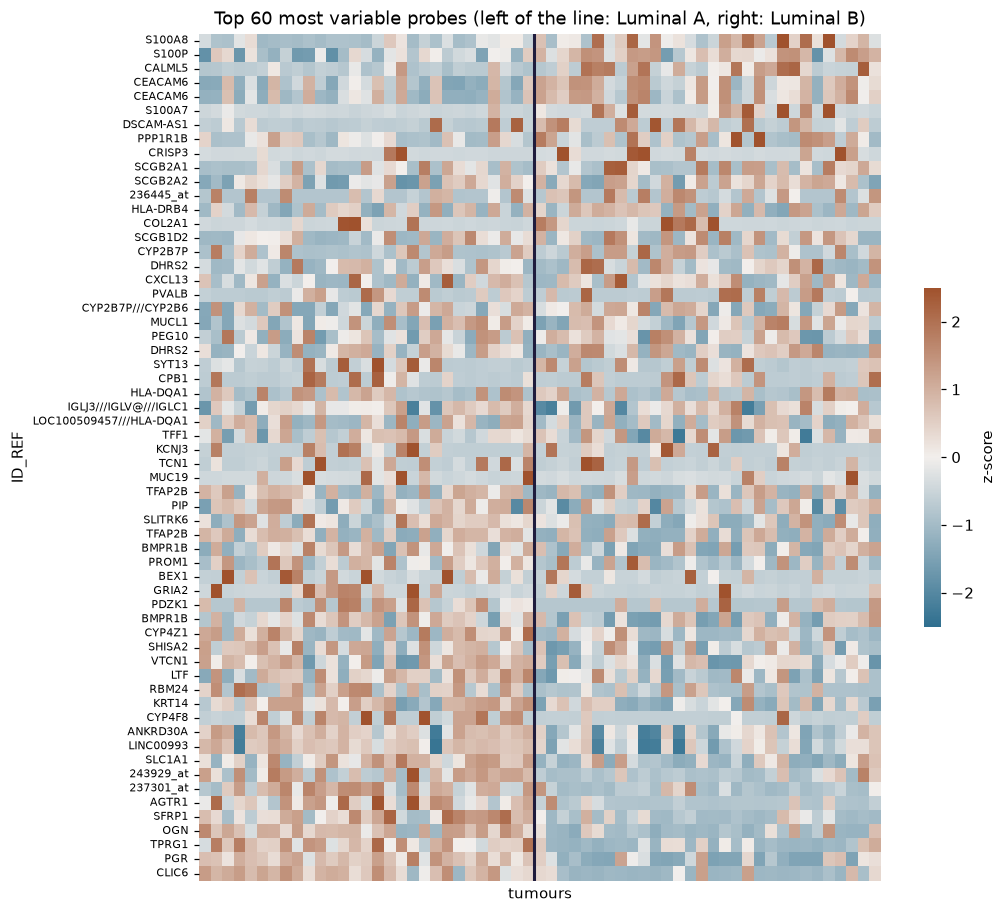

Caption: the bottom block, including the progesterone receptor PGR, is higher in Luminal A; the rest varies within both groups.


In [10]:
top60 = expr.var(axis=1).nlargest(60).index
z = expr.loc[top60, order]
z = z.sub(z.mean(axis=1), axis=0).div(z.std(axis=1), axis=0)
z = z.loc[(z.iloc[:, :29].mean(axis=1) - z.iloc[:, 29:].mean(axis=1)).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(z, cmap=sns.blend_palette(["#2F6F8F", "#F2EFEC", "#A0522D"], as_cmap=True), center=0, vmin=-2.5, vmax=2.5,
            xticklabels=False, yticklabels=[symbol[p] or p for p in z.index], cbar_kws=dict(label="z-score", shrink=0.4), ax=ax)
ax.axvline(29, color=INK, lw=2)
ax.set(title="Top 60 most variable probes (left of the line: Luminal A, right: Luminal B)", xlabel="tumours")
ax.tick_params(axis="y", labelsize=7)
save(fig, "04c_heatmap")
print("Caption: the bottom block, including the progesterone receptor PGR, is higher in Luminal A; the rest varies within both groups.")

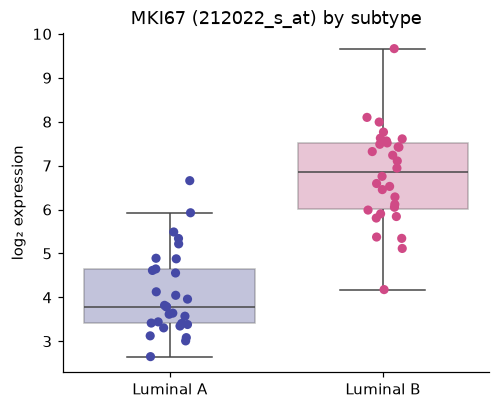

MKI67 probes in the annotation: ['212020_s_at', '212021_s_at', '212022_s_at', '212023_s_at']
Caption: MKI67 is 6.4× higher in Luminal B (p = 5e-14), as expected.


In [11]:
mki = [p for p in expr.index if "MKI67" in symbols_of[p]]          # probe IDs from the annotation
MKI = max(mki, key=lambda p: expr.loc[p].mean())
meta["MKI67"] = expr.loc[MKI].values
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=meta, x="subtype", y="MKI67", hue="subtype", palette=PAL, showfliers=False, boxprops=dict(alpha=0.35), ax=ax)
sns.stripplot(data=meta, x="subtype", y="MKI67", hue="subtype", palette=PAL, ax=ax, size=6)
ax.set(title=f"MKI67 ({MKI}) by subtype", xlabel="", ylabel="log₂ expression")
save(fig, "04d_mki67")
d = meta.MKI67[is_b].mean() - meta.MKI67[~is_b].mean()
assert d > 0, "MKI67 is not higher in Luminal B: check the labels"
print(f"MKI67 probes in the annotation: {mki}")
print(f"Caption: MKI67 is {2**d:.1f}× higher in Luminal B (p = {stats.ttest_ind(meta.MKI67[is_b], meta.MKI67[~is_b], equal_var=False).pvalue:.0e}), as expected.")

**What we found:** the tumours are well normalised. PCA shows the subtypes mostly apart on PC1 but touching in the middle, like one continuum with a line through it. The most variable genes are mostly *not* cell-division genes, and *PGR* is higher in Luminal A. *MKI67* is 6.4× higher in Luminal B, which confirms the labels.

## Stage 5 · Differential expression
- **What:** test every probe with Welch's t-test (Mann–Whitney U as a check) and correct with Benjamini–Hochberg.
- **Why:** at p < 0.05, about 1,430 of 28,592 probes would look significant by chance alone.
- **Look for:** far more than 1,430 hits, and the strongest ones higher in Luminal B.

In [12]:
A, B = expr.values[:, ~is_b], expr.values[:, is_b]
de = pd.DataFrame({"symbol": symbol.values, "mean_A": A.mean(1), "mean_B": B.mean(1), "log2FC": B.mean(1) - A.mean(1),
                   "p": stats.ttest_ind(B, A, axis=1, equal_var=False).pvalue,
                   "p_mw": stats.mannwhitneyu(B, A, axis=1).pvalue}, index=expr.index)
de["q"] = multipletests(de.p, method="fdr_bh")[1]
de["q_mw"] = multipletests(de.p_mw, method="fdr_bh")[1]
de = de.sort_values("p")
sig = de.q < 0.05
print(f"p < 0.05: {(de.p < 0.05).sum():,} (chance: {0.05 * len(de):,.0f}) · FDR < 5%: {sig.sum():,} "
      f"({(sig & (de.log2FC > 0)).sum():,} up in B, {(sig & (de.log2FC < 0)).sum():,} up in A)")
print(f"Mann–Whitney agrees on {((de.q < .05) == (de.q_mw < .05)).mean():.1%} of probes · gene-symbol match rate {(symbol != '').mean():.1%}")

p < 0.05: 11,305 (chance: 1,430) · FDR < 5%: 8,269 (4,122 up in B, 4,147 up in A)
Mann–Whitney agrees on 94.9% of probes · gene-symbol match rate 89.9%


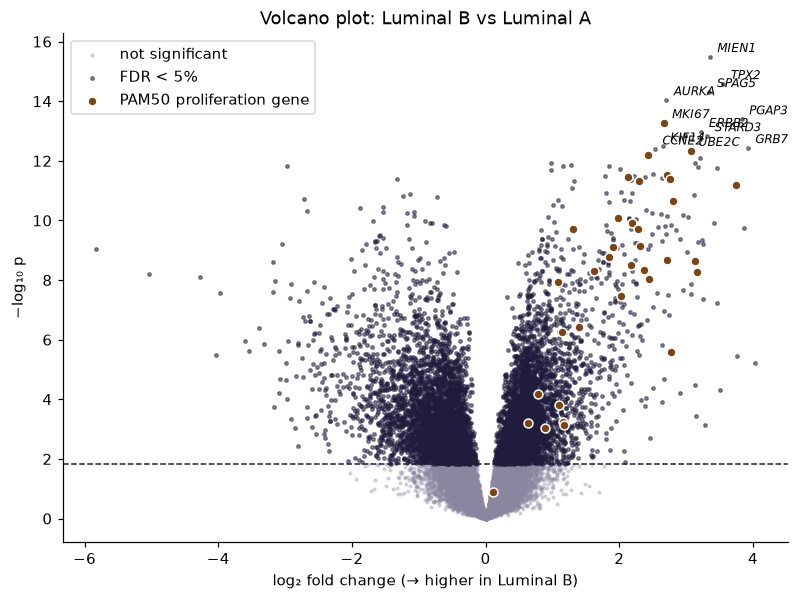

Caption: the strongest differences (top right) are cell-division genes and a group of genes from chromosome 17 (ERBB2, GRB7, STARD3).


In [13]:
PAM50 = ["ANLN", "BIRC5", "CCNB1", "CCNE1", "CDC20", "CDC6", "NUF2", "CENPF", "CEP55", "EXO1", "KIF2C",
         "NDC80", "MELK", "MKI67", "MYBL2", "ORC6", "PTTG1", "RRM2", "TYMS", "UBE2C", "UBE2T"]
de["pam50"] = de.symbol.str.split("///").apply(lambda g: bool(set(g) & set(PAM50)))
y_ = -np.log10(de.p)
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.scatter(de.log2FC[~sig], y_[~sig], s=3, color=MUTED, alpha=0.3, label="not significant")
ax.scatter(de.log2FC[sig], y_[sig], s=5, color=INK, alpha=0.5, label="FDR < 5%")
ax.scatter(de.log2FC[de.pam50], y_[de.pam50], s=34, color=PROLIF, edgecolor="white", label="PAM50 proliferation gene")
ax.axhline(-np.log10(de.p[sig].max()), color=INK, ls="--", lw=1)
for pid, r in de[de.symbol != ""].drop_duplicates("symbol").head(12).iterrows():
    ax.annotate(r.symbol, (r.log2FC, -np.log10(r.p)), xytext=(5, 3), textcoords="offset points", fontsize=8, fontstyle="italic")
ax.set(title="Volcano plot: Luminal B vs Luminal A", xlabel="log₂ fold change (→ higher in Luminal B)", ylabel="−log₁₀ p"); ax.legend()
save(fig, "05b_volcano")
print("Caption: the strongest differences (top right) are cell-division genes and a group of genes from chromosome 17 (ERBB2, GRB7, STARD3).")

In [14]:
show = de.head(30)[["symbol", "mean_A", "mean_B", "log2FC", "p", "q"]]
Path("results").mkdir(exist_ok=True); de.head(2000).to_csv("results/differential_expression_top2000.csv")
show.style.format({"mean_A": "{:.2f}", "mean_B": "{:.2f}", "log2FC": "{:+.2f}", "p": "{:.1e}", "q": "{:.1e}"})

,symbol,mean_A,mean_B,log2FC,p,q
ID_REF,,,,,,
224447_s_at,MIEN1,9.07,12.42,+3.35,3.2e-16,9.1e-12
210052_s_at,TPX2,4.25,7.81,+3.55,2.6e-15,3.7e-11
203145_at,SPAG5,3.49,6.83,+3.35,4.8e-15,4.6e-11
204092_s_at,AURKA,4.08,6.78,+2.70,9.0e-15,6.4e-11
55616_at,PGAP3,7.11,10.94,+3.83,4.0e-14,2.3e-10
212022_s_at,MKI67,4.09,6.77,+2.68,5.3e-14,2.5e-10
216836_s_at,ERBB2,10.34,13.56,+3.23,1.0e-13,4.3e-10
208079_s_at,AURKA,5.25,8.23,+2.98,1.3e-13,4.6e-10
202991_at,STARD3,6.65,9.96,+3.31,1.5e-13,4.6e-10


**What we found:** 8,269 probes (5,631 genes) pass FDR 5%, against about 1,430 expected by chance, and Mann–Whitney agrees for 95% of probes. The top of the list is two groups of genes: cell-division genes such as *TPX2*, *AURKA* and *MKI67*, and genes that sit together on chromosome 17 (*ERBB2*, *GRB7*, *STARD3*, *PGAP3*, *MIEN1*). The annotation maps 89.9% of probes to a gene symbol.

## Stage 6 · Biological interpretation
- **What:** measure how much of the signal is cell division (using the gene sets we declared), and test which biological processes are over-represented.
- **Why:** this tests the hypothesis directly and turns a gene list into biology.
- **Look for:** cell-division genes crowding the top of the list, far above their 3% share of the chip.

In [15]:
go = annot["GO:Process ID"].reindex(expr.index).fillna("")
de["cell_cycle"] = (go.str.contains("GO:0007049|GO:0051301") | de.pam50.reindex(expr.index)).reindex(de.index)
for n in (50, 100):
    print(f"Top {n}: {de.head(n).cell_cycle.sum()} cell-cycle probes ({de.head(n).pam50.sum()} PAM50)")
odds, p_f = stats.fisher_exact(pd.crosstab(de.q < 0.05, de.cell_cycle).values[::-1, ::-1], alternative="greater")
print(f"All significant: {de.cell_cycle[de.q < .05].mean():.1%} cell-cycle vs {de.cell_cycle.mean():.1%} on the chip (odds ratio {odds:.1f}, p = {p_f:.0e})")

Top 50: 22 cell-cycle probes (9 PAM50)
Top 100: 30 cell-cycle probes (13 PAM50)
All significant: 4.3% cell-cycle vs 3.0% on the chip (odds ratio 1.8, p = 2e-15)


In [16]:
# Offline GO enrichment (hypergeometric test, BH-corrected) for genes higher in each subtype
names = annot["GO:Process"].reindex(expr.index).fillna("")
terms, tname = {}, {}
for pid in expr.index:
    for tid, tn in zip(go[pid].split("///"), names[pid].split("///")):
        if tid:
            tname[tid] = tn
            terms.setdefault(tid, set()).update(g for g in symbols_of[pid] if g)
universe = set().union(*terms.values())

def enrich(hits):
    hits &= universe
    rows = [(tname[t], len(g & hits), len(g), stats.hypergeom.sf(len(g & hits) - 1, len(universe), len(g), len(hits)))
            for t, g in terms.items() if 10 <= len(g) <= 500 and len(g & hits) >= 3]
    r = pd.DataFrame(rows, columns=["process", "hits", "size", "p"]).sort_values("p")
    r["q"] = multipletests(r.p, method="fdr_bh")[1]
    return r.head(6)[["process", "hits", "size", "q"]]

genes = lambda f: {g for s in f.symbol for g in s.split("///") if g}
print("Higher in Luminal B:"); display(enrich(genes(de[(de.q < .05) & (de.log2FC > 0)])))
print("Higher in Luminal A:"); display(enrich(genes(de[(de.q < .05) & (de.log2FC < 0)])))

Higher in Luminal B:


,process,hits,size,q
192,cell division,142,318,4.931855e-17
702,anaphase-promoting complex-dependent catabolic...,51,81,1.124825e-12
711,regulation of cellular amino acid metabolic pr...,37,51,6.599969e-12
334,CENP-A containing nucleosome assembly,32,42,3.091617e-11
710,positive regulation of ubiquitin-protein ligas...,48,80,4.396032e-11
705,negative regulation of ubiquitin-protein ligas...,46,76,7.501176e-11


Higher in Luminal A:


,process,hits,size,q
872,SRP-dependent cotranslational protein targetin...,87,140,5.830134e-30
876,viral transcription,93,164,5.350665e-28
875,translational initiation,101,189,8.248003e-28
292,"nuclear-transcribed mRNA catabolic process, no...",94,182,2.090484e-24
495,rRNA processing,104,275,2.229927e-14
556,translation,98,257,7.793040e-14


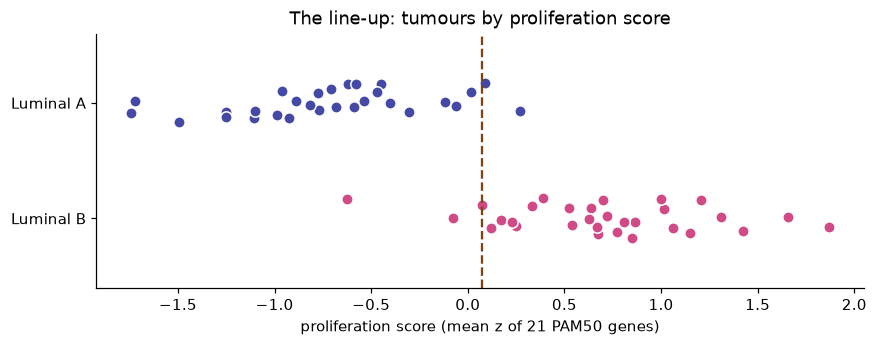

Caption: one line on the score puts 93% of tumours on their labelled side (chosen with hindsight, so optimistic).


In [17]:
# A proliferation score per tumour: mean z-score of the declared PAM50 genes (brightest probe each)
rep = de[de.pam50].assign(g=lambda d: d.symbol.str.split("///").str[0], m=lambda d: d.mean_A + d.mean_B)
PROLIF_PROBES = rep.sort_values("m", ascending=False).drop_duplicates("g").index.tolist()
zscore = lambda probes: expr.loc[probes].sub(expr.loc[probes].mean(axis=1), axis=0).div(expr.loc[probes].std(axis=1), axis=0).mean()
meta["prolif"] = zscore(PROLIF_PROBES).values
cuts = np.sort(meta.prolif); acc = [((meta.prolif >= c) == is_b).mean() for c in cuts]
best_cut = cuts[int(np.argmax(acc))]

fig, ax = plt.subplots(figsize=(9, 3))
for st, y0 in (("Luminal A", 1), ("Luminal B", 0)):
    m = (meta.subtype == st).values
    ax.scatter(meta.prolif[m], y0 + np.random.default_rng(1).uniform(-.18, .18, m.sum()), s=55, color=PAL[st], edgecolor="white")
ax.axvline(best_cut, color=PROLIF, ls="--")
ax.set(yticks=[0, 1], yticklabels=["Luminal B", "Luminal A"], ylim=(-.6, 1.6),
       title="The line-up: tumours by proliferation score", xlabel="proliferation score (mean z of 21 PAM50 genes)")
save(fig, "06a_lineup")
print(f"Caption: one line on the score puts {max(acc):.0%} of tumours on their labelled side (chosen with hindsight, so optimistic).")

**An unplanned finding (exploratory).** The chromosome-17 genes from Stage 5 form the **HER2 amplicon**, a piece of DNA that some tumours copy many times. Because we chose these genes after seeing the results, we label this exploratory.

25 of 30 Luminal B tumours have more ERBB2 than any Luminal A tumour · correlation with the proliferation score r = 0.69


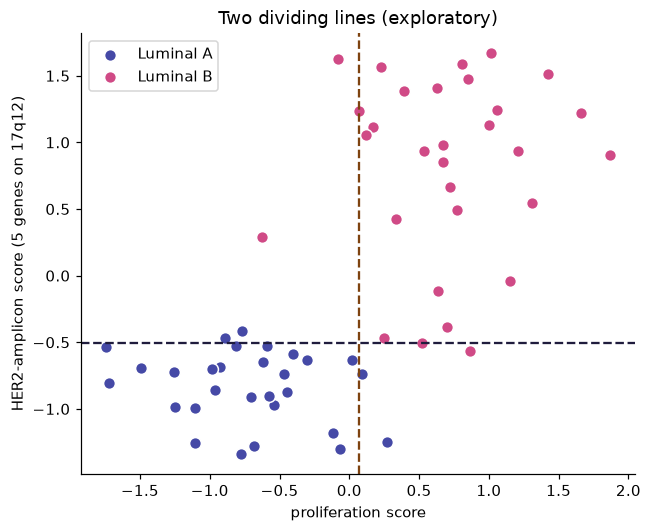

Caption: Luminal B tumours are fast-dividing, HER2-high, or both.


In [18]:
AMPLICON = ["ERBB2", "GRB7", "STARD3", "PGAP3", "MIEN1"]
AMP_PROBES = [max([p for p in expr.index if g in symbols_of[p]], key=lambda p: expr.loc[p].mean()) for g in AMPLICON]
meta["her2"] = zscore(AMP_PROBES).values
erbb2 = expr.loc[AMP_PROBES[0]]
hcuts = np.sort(meta.her2); her2_cut = hcuts[int(np.argmax([((meta.her2 >= c) == is_b).mean() for c in hcuts]))]
print(f"{(erbb2[is_b] > erbb2[~is_b].max()).sum()} of 30 Luminal B tumours have more ERBB2 than any Luminal A tumour · "
      f"correlation with the proliferation score r = {np.corrcoef(meta.prolif, meta.her2)[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 5.2))
for st in PAL:
    m = (meta.subtype == st).values
    ax.scatter(meta.prolif[m], meta.her2[m], color=PAL[st], label=st, s=60, edgecolor="white")
ax.axvline(best_cut, color=PROLIF, ls="--"); ax.axhline(her2_cut, color=INK, ls="--")
ax.set(title="Two dividing lines (exploratory)", xlabel="proliferation score", ylabel="HER2-amplicon score (5 genes on 17q12)"); ax.legend()
save(fig, "06c_two_lines")
print("Caption: Luminal B tumours are fast-dividing, HER2-high, or both.")

**What we found:**
- Cell-division genes dominate the *top* of the list, with 22 of the top 50 and 30 of the top 100. Across all significant genes they are enriched but modestly (4.3% vs 3.0% of the chip, odds ratio 1.8).
- Genes higher in Luminal B are enriched for cell division, chromosome segregation and DNA replication. Genes higher in Luminal A lean towards protein production and extracellular matrix.
- The proliferation score alone separates the subtypes well (93% at the best line).
- *Exploratory:* the HER2 amplicon is a second dividing line. 25 of 30 Luminal B tumours have more *ERBB2* than any Luminal A tumour, which fits the clinical rule that hormone-sensitive, HER2-positive tumours count as Luminal B.

## Stage 7 · Machine learning
- **What:** logistic regression, compared on a ladder of baselines that keep or remove the proliferation genes.
- **Why:** with 59 samples and ~28,600 features it is easy to overfit, so gene selection and tuning stay *inside* the training folds (nested, stratified cross-validation).
- **Look for:** whether 21 proliferation genes match the full model, and what is left when they are removed.

Rungs marked * were added after Stage 6, so they are exploratory.

In [19]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X, y = expr.T.values, is_b.astype(int)
col = {p: i for i, p in enumerate(expr.index)}
idx = lambda mask: np.where(mask)[0]
prolif_cols, her2_cols, mki_col = [col[p] for p in PROLIF_PROBES], [col[p] for p in AMP_PROBES], [col[MKI]]
pam50_all = idx(de.pam50.reindex(expr.index).values)
cc_all = idx(de.cell_cycle.reindex(expr.index).values)
amp_all = idx(symbols_of.apply(lambda g: bool(set(g) & set(AMPLICON))).values)

class Keep(BaseEstimator, TransformerMixin):
    # Keep a fixed list of columns.
    def __init__(self, cols=None): self.cols = cols
    def fit(self, X, y=None): return self
    def transform(self, X): return X[:, self.cols]

class Drop(BaseEstimator, TransformerMixin):
    # Drop columns, plus (optionally) any column correlated |r| >= 0.4 with a score, computed on the training fold only.
    def __init__(self, drop=None, scores=None): self.drop, self.scores = drop, scores
    def fit(self, X, y=None):
        keep = np.ones(X.shape[1], bool); keep[self.drop] = False
        Z = (X - X.mean(0)) / (X.std(0) + 1e-9)
        for cols in self.scores or []:
            s = Z[:, cols].mean(1)
            keep &= np.abs((Z * ((s - s.mean()) / s.std())[:, None]).mean(0)) < 0.4
        self.keep_ = np.where(keep)[0]; return self
    def transform(self, X): return X[:, self.keep_]

LR = lambda: LogisticRegression(solver="liblinear", max_iter=2000)
small = lambda cols: (Pipeline([("sel", Keep(cols)), ("sc", StandardScaler()), ("clf", LR())]), {"clf__C": [0.05, 0.5]})
wide = lambda drop=None: (Pipeline(([("drop", drop)] if drop is not None else []) + [("k", SelectKBest(f_classif)), ("sc", StandardScaler()), ("clf", LR())]),
                          {"k__k": [20, 100, 500], "clf__C": [0.05, 0.5]})
no_prolif = np.union1d(pam50_all, cc_all)
MODELS = {
    "Dummy (majority class)": (Pipeline([("clf", DummyClassifier())]), None),
    "MKI67 alone": small(mki_col),
    "Proliferation genes only (21)": small(prolif_cols),
    "HER2 amplicon only (5) *": small(her2_cols),
    "Both lines (26) *": small(prolif_cols + her2_cols),
    "No PAM50 genes": wide(Drop(pam50_all)),
    "No cell-cycle genes": wide(Drop(no_prolif)),
    "No proliferation signal at all": wide(Drop(no_prolif, [prolif_cols])),
    "Neither line *": wide(Drop(np.union1d(no_prolif, amp_all), [prolif_cols, her2_cols])),
    "Full model (all probes)": wide(),
}

In [20]:
outer = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED).split(X, y))
inner = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)

def evaluate(pipe, grid, labels):
    folds, oof = [], np.zeros((4, len(labels)))
    for f, (tr, te) in enumerate(outer):
        m = (GridSearchCV(clone(pipe), grid, cv=inner, scoring="roc_auc", n_jobs=-1) if grid else clone(pipe)).fit(X[tr], labels[tr])
        pr = m.predict_proba(X[te])[:, 1]; oof[f // 5, te] = pr; pred = pr >= 0.5
        folds.append(dict(auc=roc_auc_score(labels[te], pr), acc=(pred == labels[te]).mean(),
                          errA=pred[labels[te] == 0].mean(), errB=(~pred[labels[te] == 1]).mean()))
    return pd.DataFrame(folds), oof

t0 = time.time()
results, oof = {}, {}
for name, (pipe, grid) in MODELS.items():
    results[name], oof[name] = evaluate(pipe, grid, y)
ladder = pd.DataFrame({n: {"ROC-AUC": f"{r.auc.mean():.2f} ± {r.auc.std():.2f}", "accuracy": f"{r.acc.mean():.0%}",
                           "Luminal A called B": f"{r.errA.mean():.0%}", "Luminal B called A": f"{r.errB.mean():.0%}"}
                       for n, r in results.items()}).T
print(f"Nested CV: 5 folds × 4 repeats, done in {time.time() - t0:.0f} s")
ladder

Nested CV: 5 folds × 4 repeats, done in 173 s


,ROC-AUC,accuracy,Luminal A called B,Luminal B called A
Dummy (majority class),0.50 ± 0.00,51%,100%,0%
MKI67 alone,0.97 ± 0.05,89%,10%,12%
Proliferation genes only (21),0.98 ± 0.04,95%,3%,7%
HER2 amplicon only (5) *,0.98 ± 0.02,90%,0%,20%
Both lines (26) *,1.00 ± 0.01,98%,0%,3%
No PAM50 genes,0.99 ± 0.02,97%,1%,4%
No cell-cycle genes,0.99 ± 0.02,96%,0%,8%
No proliferation signal at all,0.97 ± 0.05,90%,5%,15%
Neither line *,0.96 ± 0.05,89%,8%,14%
Full model (all probes),0.99 ± 0.03,97%,1%,4%


In [21]:
# Is the full model really better than 21 genes? Corrected paired t-test (Nadeau & Bengio, 2003)
d = results["Full model (all probes)"].auc - results["Proliferation genes only (21)"].auc
t = d.mean() / np.sqrt((1 / len(d) + 12 / 47) * d.var(ddof=1))
print(f"Full − proliferation-only: AUC {d.mean():+.3f}, corrected p = {2 * stats.t.sf(abs(t), len(d) - 1):.2f}")

# Leakage check: with shuffled labels a leak-free pipeline should score about 0.5 (three shuffles each)
rng = np.random.default_rng(SEED)
for name in ("Full model (all probes)", "Neither line *"):
    s = [evaluate(*MODELS[name], rng.permutation(y))[0].auc.mean() for _ in range(3)]
    print(f"{name} with shuffled labels: AUC {np.mean(s):.2f} (shuffles: {', '.join(f'{v:.2f}' for v in s)})")

Full − proliferation-only: AUC +0.009, corrected p = 0.35


Full model (all probes) with shuffled labels: AUC 0.48 (shuffles: 0.38, 0.62, 0.44)


Neither line * with shuffled labels: AUC 0.50 (shuffles: 0.65, 0.55, 0.30)


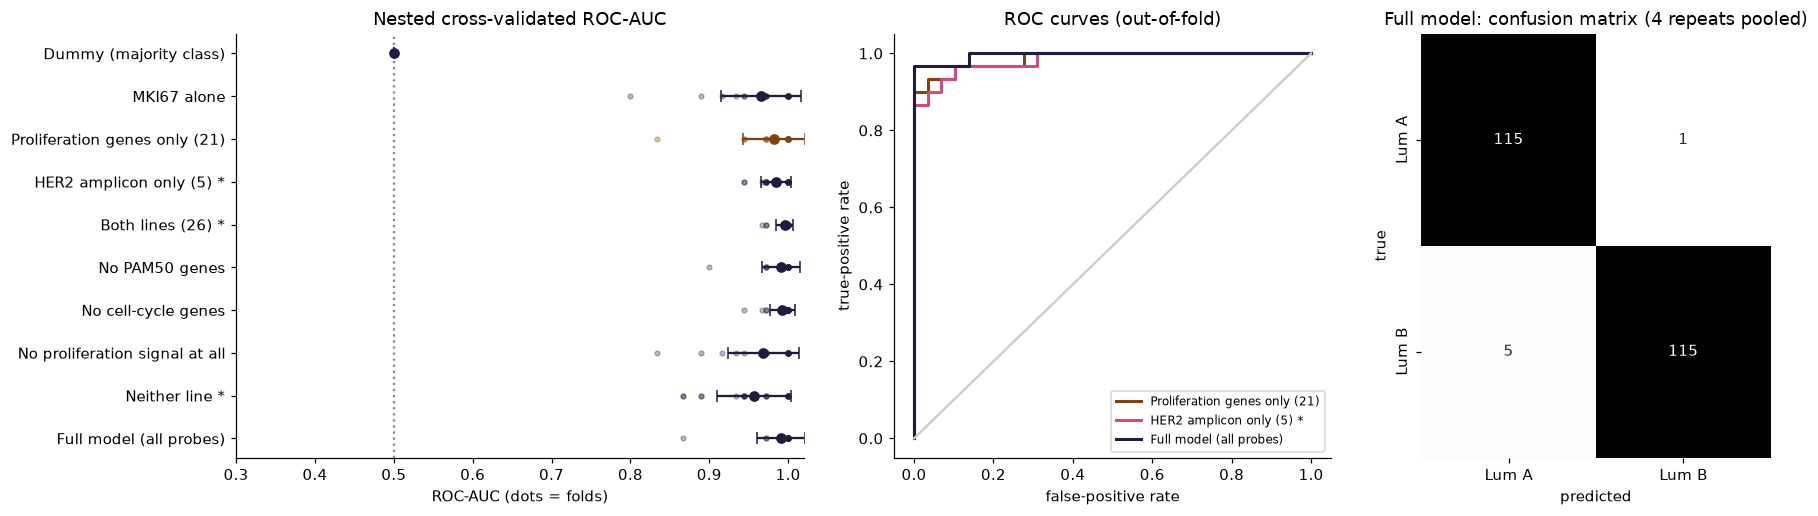

Caption: 21 proliferation genes nearly match all probes, removing proliferation barely lowers the score, and most errors are Luminal B called A.


In [22]:
fig, (ax, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw=dict(width_ratios=[1.3, 1, 0.8]))
for i, (name, r) in enumerate(results.items()):
    c = PROLIF if "Proliferation genes" in name else INK
    ax.scatter(r.auc, np.full(len(r), i), s=10, color=c, alpha=0.3)
    ax.errorbar(r.auc.mean(), i, xerr=r.auc.std(), fmt="o", color=c, capsize=4)
ax.axvline(0.5, color=MUTED, ls=":")
ax.set(yticks=range(len(results)), yticklabels=list(results), xlim=(0.3, 1.02), title="Nested cross-validated ROC-AUC", xlabel="ROC-AUC (dots = folds)")
ax.invert_yaxis()
for name in ("Proliferation genes only (21)", "HER2 amplicon only (5) *", "Full model (all probes)"):
    fpr, tpr, _ = roc_curve(y, oof[name].mean(0))
    ax2.plot(fpr, tpr, lw=2, label=name, color=PROLIF if "Prolif" in name else (LUM_B if "HER2" in name else INK))
ax2.plot([0, 1], [0, 1], color="#ccc"); ax2.legend(fontsize=8)
ax2.set(title="ROC curves (out-of-fold)", xlabel="false-positive rate", ylabel="true-positive rate")
pred = oof["Full model (all probes)"] >= 0.5
cm = [[((pred == p) & (y == t)).sum() for p in (0, 1)] for t in (0, 1)]
sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Greys", xticklabels=["Lum A", "Lum B"], yticklabels=["Lum A", "Lum B"], ax=ax3)
ax3.set(title="Full model: confusion matrix (4 repeats pooled)", xlabel="predicted", ylabel="true")
save(fig, "07_ladder_roc")
print("Caption: 21 proliferation genes nearly match all probes, removing proliferation barely lowers the score, and most errors are Luminal B called A.")

**What we found:**
- 21 proliferation genes reach AUC 0.98 against 0.99 for all probes, a gap within noise (corrected p = 0.35). Even *MKI67* alone reaches 0.97.
- Removing proliferation does *not* break the classifier (0.97), partly because the HER2 amplicon also separates the groups (0.98*). With both removed, the score is still 0.96.
- With shuffled labels the score drops to about 0.5, so the pipeline does not leak.
- Most remaining errors are Luminal B tumours called Luminal A, which is the costly mistake.

## Stage 8 · Conclusions and limitations
1. **Expression:** the subtypes differ clearly, but they form one continuum with a dividing line rather than two separate groups.
2. **Significant genes:** 8,269 probes pass FDR 5%, led by cell-division and HER2-amplicon genes.
3. **Biology:** cell division is the biggest single theme. HER2 amplification is a second, unplanned signal (exploratory).
4. **Classification:** 21 proliferation genes classify about as well as all genes, but they are not the only route to a high score.

**Answer:** the subtypes differ mostly in how fast the cells divide, plus HER2 status. Our hypothesis was **partly supported**.

**Limitations**
- With only 59 tumours, every number is a rough estimate.
- The labels are built from expression (and probably HER2 status), so a high score is partly guaranteed.
- This is one French cohort. Kenyan patients tend to be younger, with more triple-negative disease, so the results need local validation.
- Subtype labels disagree between methods, and the normalisation is the submitters', not ours.

**Research use only:** this must not inform clinical decisions. Calling a Luminal B tumour Luminal A could mean chemotherapy is wrongly withheld.

**Next steps:** validate on an independent cohort (TCGA or METABRIC), test on African patients, and use an independent label such as Ki-67 staining or patient outcome.